In [1]:
# Sentiment Analysis for Financial News (дз 1-7)

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [3]:
# Единый порядок категорий для таблиц и графиков.
CLASS_ORDER = ["negative", "neutral", "positive"]

In [4]:
df = pd.read_csv(
    'all-data.csv',
    encoding='latin-1',
    header=None,
    names=['sentiment', 'text']
)

# Убираем случайные пробелы и приводим только метки к нижнему регистру.
df["sentiment"] = df["sentiment"].astype("string").str.strip().str.lower()

print("Размер:", df.shape)
display(df.head())

Размер: (4846, 2)


,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


In [5]:
print("Размерность (строки, колонки):", df.shape)
print("Названия колонок:", df.columns.tolist())

print("\nТипы колонок:")
print(df.dtypes)

print("\nПодробная информация:")
df.info()

Размерность (строки, колонки): (4846, 2)
Названия колонок: ['sentiment', 'text']

Типы колонок:
sentiment    string[python]
text                 object
dtype: object

Подробная информация:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  4846 non-null   string
 1   text       4846 non-null   object
dtypes: object(1), string(1)
memory usage: 75.8+ KB


In [6]:
print("Пропуски по колонкам:")
display(df.isna().sum().rename("missing_count").to_frame())

empty_text_mask = df["text"].fillna("").astype(str).str.strip().eq("")
print("Пустых текстов (включая пробелы и NaN):", empty_text_mask.sum())

print("Полных дубликатов строк:", df.duplicated().sum())
print("Повторяющихся текстов (без учёта sentiment):", df.duplicated(subset=["text"]).sum())

unexpected_labels = sorted(set(df["sentiment"].dropna().unique()) - set(CLASS_ORDER))
print("Неожиданные названия классов:", unexpected_labels if unexpected_labels else "нет")

Пропуски по колонкам:


,missing_count
sentiment,0
text,0


Пустых текстов (включая пробелы и NaN): 0
Полных дубликатов строк: 6
Повторяющихся текстов (без учёта sentiment): 8
Неожиданные названия классов: нет


In [7]:
# Удаляем полные дубликаты
df = df.drop_duplicates().reset_index(drop=True)

print('Количество строк:', len(df))

Количество строк: 4840


In [8]:
conflicts = df.groupby('text')['sentiment'].nunique()

conflicts = conflicts[conflicts > 1]

print('Текстов с разными метками:', len(conflicts))

Текстов с разными метками: 2


In [9]:
df[df['text'].isin(conflicts.index)].sort_values('text')

,sentiment,text
78,neutral,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...
79,positive,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...
788,positive,The Group 's business is balanced by its broad...
789,neutral,The Group 's business is balanced by its broad...


In [10]:
# Удаляем конфликтующие записи
df = df[~df['text'].isin(conflicts.index)].reset_index(drop=True)

In [11]:
print('Количество строк:', len(df))
print('Полных дубликатов:', df.duplicated().sum())
print('Повторов текстов:', df.duplicated(subset=['text']).sum())

Количество строк: 4836
Полных дубликатов: 0
Повторов текстов: 0


In [12]:
class_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)
class_share = 100 * class_counts / len(df)

class_distribution = pd.DataFrame({
    "Количество": class_counts,
    "Доля, %": class_share.round(2)
})

display(class_distribution)
print("Всего строк по известным классам:", class_counts.sum())

,Количество,"Доля, %"
sentiment,,
negative,604,12.49
neutral,2871,59.37
positive,1361,28.14


Всего строк по известным классам: 4836


In [13]:
texts = df["text"].fillna("").astype(str)
df["text_length"] = texts.str.len()
df["word_count"] = texts.str.split().str.len()

print("Описательная статистика (символы и слова):")
display(df[["text_length", "word_count"]].describe().round(2))

print("\nСредние характеристики по классам:")
display(
    df.groupby("sentiment")[["text_length", "word_count"]]
    .mean()
    .reindex(CLASS_ORDER)
    .round(2)
)

Описательная статистика (символы и слова):


,text_length,word_count
count,4836.00,4836.00
mean,128.04,23.09
std,56.39,9.94
min,9.00,2.00
25%,84.00,16.00
50%,119.00,21.00
75%,163.00,29.00
max,315.00,81.00



Средние характеристики по классам:


,text_length,word_count
sentiment,,
negative,125.76,23.92
neutral,124.94,22.15
positive,135.60,24.68


In [14]:
# Выводим несколько примеров текстов из разных классов
for sentiment in ['positive', 'negative', 'neutral']:
    print(f'\n=== {sentiment.upper()} ===')

    examples = df[df['sentiment'] == sentiment]['text'].head(3)

    for text in examples:
        print(f'- {text}\n')


=== POSITIVE ===
- With the new production plant the company would increase its capacity to meet the expected increase in demand and would improve the use of raw materials and therefore increase the production profitability .

- According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-term net sales growth in the range of 20 % -40 % with an operating profit margin of 10 % -20 % of net sales .

- FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is aggressively pursuing its growth strategy by increasingly focusing on technologically more demanding HDI printed circuit boards PCBs .


=== NEGATIVE ===
- The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; contrary to earlier layoffs the company contracted the ranks of its office workers , the daily Postimees reported .

- A tinyurl link takes users to a scamming site promising that users can earn thousands of dollars by becoming a Google ( NASDAQ : GO

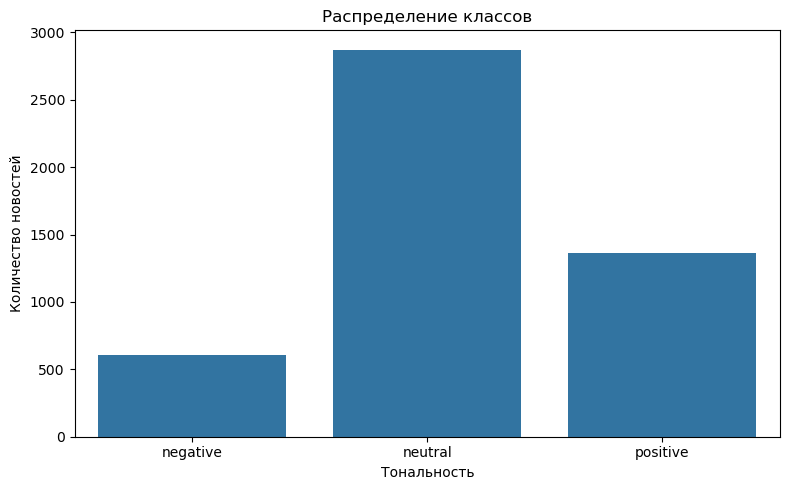

In [15]:
# График распределения классов
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=CLASS_ORDER
)

plt.title("Распределение классов")
plt.xlabel("Тональность")
plt.ylabel("Количество новостей")
plt.tight_layout()

plt.savefig("sentiment_distribution.png", dpi=150)
plt.show()


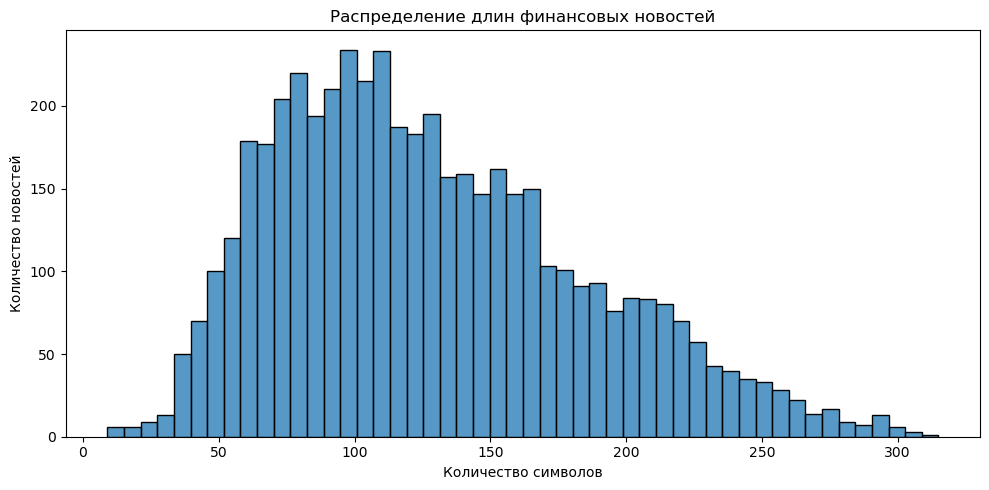

In [16]:
# График распределения длин текстов
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    bins=50
)

plt.title("Распределение длин финансовых новостей")
plt.xlabel("Количество символов")
plt.ylabel("Количество новостей")
plt.tight_layout()

plt.savefig("text_length_distribution.png", dpi=150)
plt.show()

# Итоги Дня 1 - EDA финансовых новостей

## 1. Общая характеристика датасета

Для проекта используется датасет **Financial Sentiment Analysis**, содержащий финансовые новости на английском языке.

- Исходное количество записей: **4 846**
- Количество признаков: **2** (`text`, `sentiment`)
- Задача: многоклассовая классификация тональности текста
- Целевые классы: `negative`, `neutral`, `positive`

## 2. Проверка качества данных

В ходе первичного анализа установлено:

- Пропущенные значения отсутствуют.
- Пустых текстов нет.
- Обнаружено 6 полных дубликатов строк.
- Обнаружено 2 текста с противоречивыми метками классов.

После удаления 6 дубликатов и 4 записей с конфликтующими метками осталось **4 836 уникальных текстов**.

## 3. Распределение классов

| Класс | Количество | Доля |
|---|---:|---:|
| Negative | 604 | 12,49% |
| Neutral | 2 871 | 59,37% |
| Positive | 1 361 | 28,14% |
| **Всего** | **4 836** | **100%** |

**Наблюдение:** распределение классов несбалансированное. Нейтральные новости составляют большинство, а негативные — наименьшую группу.

Это необходимо учитывать при обучении модели и оценке её качества.

## 4. Анализ длины текстов

Статистические характеристики:

- Средняя длина: **128,04 символа**
- Медианная длина: **119 символов**
- Минимальная длина: **9 символов**
- Максимальная длина: **315 символов**
- Среднее количество слов: **23,09**

Средняя длина по классам:

| Класс | Символов | Слов |
|---|---:|---:|
| Negative | 125,76 | 23,92 |
| Neutral | 124,94 | 22,15 |
| Positive | 135,60 | 24,68 |

**Наблюдение:** позитивные новости в среднем немного длиннее нейтральных и негативных. Большинство текстов относительно короткие, что делает датасет подходящим для классификации финансовых предложений.

## 5. Основные выводы

1. Датасет содержит достаточно примеров для построения учебной baseline-модели классификации.
2. Качество исходных данных хорошее: отсутствуют пропуски и пустые тексты.
3. После удаления дубликатов и конфликтующих меток получен набор из 4 836 уникальных текстов.
4. Присутствует заметный дисбаланс классов.
5. Короткие тексты можно представить с помощью TF-IDF векторизации.
6. Для оценки модели целесообразно использовать **Macro F1**, а также Precision, Recall и Confusion Matrix.

## 6. План следующего этапа

На втором этапе необходимо:

- Реализовать очистку и нормализацию текстов.
- Привести тексты к нижнему регистру.
- Удалить лишние пробелы и HTML-теги.
- Подготовить функцию preprocessing.
- Преобразовать метки классов в числовой формат.

**Заключение:** День 1 позволил изучить структуру датасета, проверить качество данных и выявить особенности, которые необходимо учитывать при дальнейшем построении ML pipeline.

# День 2 - Очистка текста и подготовка признаков

**Цель:** подготовить финансовые новости для обучения
модели классификации тональности.

На данном этапе используется очищенный датасет
из Дня 1, содержащий 4 836 записи.

### Задачи
1. Очистка HTML-тегов и лишних пробелов.
2. Приведение текста к нижнему регистру.
3. Удаление некорректных примеров.
4. Преобразование классов в числовые метки.
5. Подготовка повторно используемого preprocessing.
6. Проверка результатов на примерах.

In [17]:
import re
import html

def clean_text(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [18]:

LABEL_MAP = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

def preprocess_dataframe(data):
    result = data.copy()

    result["text_clean"] = result["text"].apply(clean_text)

    result["sentiment"] = (
        result["sentiment"].astype("string").str.strip().str.lower()
    )

    result = result[
        (result["text_clean"] != "") &
        (result["sentiment"].isin(LABEL_MAP))
    ].copy()

    result["label"] = result["sentiment"].map(LABEL_MAP).astype(int)

    result["word_count_clean"] = result["text_clean"].str.split().str.len()
    result["char_count"] = result["text_clean"].str.len()
    result["dollar_count"] = result["text_clean"].str.count(r"\$")

    return result.reset_index(drop=True)


df_processed = preprocess_dataframe(df)

print("До обработки:", df.shape)
print("После обработки:", df_processed.shape)

display(df_processed.head())


До обработки: (4836, 4)
После обработки: (4836, 9)


,sentiment,text,text_length,word_count,text_clean,label,word_count_clean,char_count,dollar_count
0,neutral,"According to Gran , the company has no plans t...",127,25,"according to gran , the company has no plans t...",1,25,127,0
1,neutral,Technopolis plans to develop in stages an area...,190,31,technopolis plans to develop in stages an area...,1,31,190,0
2,negative,The international electronic industry company ...,228,36,the international electronic industry company ...,0,36,228,0
3,positive,With the new production plant the company woul...,206,33,with the new production plant the company woul...,2,33,206,0
4,positive,According to the company 's updated strategy f...,203,41,according to the company 's updated strategy f...,2,41,203,0


In [19]:

test_texts = [
    "  Apple SHARES rose 5%  ",
    "<b>Company profits</b> fell sharply",
    "Revenue    increased   by $100 million",
    "   ",
    None
]

for text in test_texts:
    print(f"Было: {text!r}")
    print(f"Стало: {clean_text(text)!r}")
    print("---")

print("\nРаспределение меток:")
print(df_processed["label"].value_counts().sort_index())

assert df_processed["text_clean"].str.len().gt(0).all()
assert df_processed["label"].isin([0, 1, 2]).all()
assert len(df_processed) == 4836

print("\nПроверки пройдены!")


Было: '  Apple SHARES rose 5%  '
Стало: 'apple shares rose 5%'
---
Было: '<b>Company profits</b> fell sharply'
Стало: 'company profits fell sharply'
---
Было: 'Revenue    increased   by $100 million'
Стало: 'revenue increased by $100 million'
---
Было: '   '
Стало: ''
---
Было: None
Стало: ''
---

Распределение меток:
label
0     604
1    2871
2    1361
Name: count, dtype: int64

Проверки пройдены!


In [20]:
df_processed.to_csv(
    "financial_news_day02.csv",
    index=False,
    encoding="utf-8"
)

print("Данные второго дня сохранены")

Данные второго дня сохранены



## Итоги Дня 2

В ходе второго этапа выполнена предобработка
финансовых новостей.

**Реализовано:**

- Очистка HTML-тегов и лишних пробелов.
- Приведение текста к нижнему регистру.
- Проверка и удаление некорректных записей.
- Преобразование классов в числовые метки:
  - negative - 0
  - neutral - 1
  - positive - 2
- Добавление признаков количества слов, символов
  и знаков доллара.
- Создание повторно используемых функций
  `clean_text()` и `preprocess_dataframe()`.

**Результат:** подготовлен датасет для дальнейшего
обучения модели классификации.


# День 3 — Baseline-модель классификации

**Цель:** построить первую модель машинного обучения
для определения тональности финансовых новостей.

### Задачи
1. Преобразовать тексты в признаки с помощью TF-IDF.
2. Разделить данные на train/test (80/20).
3. Обучить Logistic Regression.
4. Рассчитать Accuracy, Precision, Recall и F1-score.
5. Сохранить обученную модель и результаты.
6. Зафиксировать baseline для дальнейших улучшений.

**Исходные данные:** `df_processed` из Дня 2,
содержащий 4 836 обработанных текстов.

In [21]:

import json
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Используем данные второго дня
X = df_processed["text_clean"]
y = df_processed["label"]

# Разделяем данные: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Всего записей:", len(X))
print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))


Всего записей: 4836
Обучающая выборка: 3868
Тестовая выборка: 968


In [22]:

# Создаём ML Pipeline
baseline_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Обучаем на тренировочных данных
baseline_pipeline.fit(X_train, y_train)

# Получаем предсказания на test
y_pred = baseline_pipeline.predict(X_test)

print("Baseline-модель обучена!")
print("Количество предсказаний:", len(y_pred))


Baseline-модель обучена!
Количество предсказаний: 968


In [23]:

# Рассчитываем метрики
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

baseline_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("=== BASELINE RESULTS ===")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {baseline_f1:.4f}")

print("\n=== CLASSIFICATION REPORT ===")

report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    zero_division=0
)

print(report)


=== BASELINE RESULTS ===
Accuracy:        0.7707
Macro Precision: 0.7930
Macro Recall:    0.6453
Macro F1:        0.6888

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    negative       0.84      0.44      0.58       121
     neutral       0.76      0.94      0.84       575
    positive       0.77      0.56      0.65       272

    accuracy                           0.77       968
   macro avg       0.79      0.65      0.69       968
weighted avg       0.78      0.77      0.75       968



In [24]:

# Создаём директории
Path("models").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)

# Сохраняем обученный Pipeline
joblib.dump(
    baseline_pipeline,
    "models/baseline_model.joblib"
)

# Сохраняем метрики
baseline_results = {
    "model": "TF-IDF + Logistic Regression",
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(baseline_f1),
    "train_size": len(X_train),
    "test_size": len(X_test),
    "random_state": 42
}

with open(
    "reports/baseline_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        baseline_results,
        f,
        indent=4,
        ensure_ascii=False
    )

with open(
    "reports/baseline_result.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("Baseline: TF-IDF + Logistic Regression\n")
    f.write(f"Macro F1: {baseline_f1:.4f}\n\n")
    f.write(report)

print("Модель и результаты успешно сохранены!")


Модель и результаты успешно сохранены!


In [25]:

# Загружаем сохранённую модель
loaded_model = joblib.load(
    "models/baseline_model.joblib"
)

# Проверяем на новых финансовых текстах
new_texts = [
    # Позитивная новость
    "The company reported record profits and strong revenue growth.",

    # Негативная новость
    "The company suffered heavy losses and announced layoffs.",

    # Нейтральная новость
    "The board of directors will meet next Monday."
]

# Используем функцию очистки из Дня 2
clean_texts = [clean_text(text) for text in new_texts]

# Выполняем предсказания
predictions = loaded_model.predict(clean_texts)

label_names = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

for text, prediction in zip(new_texts, predictions):
    print("Text:", text)
    print("Prediction:", label_names[int(prediction)])
    print("-" * 50)


Text: The company reported record profits and strong revenue growth.
Prediction: positive
--------------------------------------------------
Text: The company suffered heavy losses and announced layoffs.
Prediction: neutral
--------------------------------------------------
Text: The board of directors will meet next Monday.
Prediction: neutral
--------------------------------------------------



# День 4 — Улучшение baseline-модели

**Цель:** протестировать несколько способов улучшения
качества классификации финансовых новостей.

### План экспериментов

1. Baseline: TF-IDF (1,2) + Logistic Regression.
2. TF-IDF (1,3) + Logistic Regression.
3. TF-IDF (1,2) + LinearSVC.
4. TF-IDF (1,2) + Logistic Regression с балансировкой классов.

### Методология

Для объективного сравнения используем:
- Одинаковые обучающие данные из Дня 3.
- Stratified 5-Fold Cross-Validation.
- Метрику Macro F1.
- Одинаковые разбиения для всех моделей.

Лучшую модель выбираем по среднему Macro F1
на кросс-валидации.

Тестовую выборку сохраняем для финальной оценки.


In [26]:

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

# Используем X_train и y_train из Дня 3

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Модели для сравнения
candidates = {
    "Baseline LogReg": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "TF-IDF Trigrams": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 3)
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "LinearSVC": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", LinearSVC(
            max_iter=3000,
            random_state=42
        ))
    ]),

    "LogReg Balanced": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

results = []

for name, model in candidates.items():
    print(f"Проверяем: {name}")

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    results.append({
        "model": name,
        "f1_mean": scores.mean(),
        "f1_std": scores.std()
    })

    print(f"Macro F1: {scores.mean():.4f}")
    print("-" * 40)

comparison = pd.DataFrame(results)

# Результат baseline на кросс-валидации
baseline_cv = comparison.loc[
    comparison["model"] == "Baseline LogReg",
    "f1_mean"
].iloc[0]

# Абсолютная и относительная разница
comparison["delta_f1"] = (
    comparison["f1_mean"] - baseline_cv
)

comparison["improvement_pct"] = (
    comparison["delta_f1"] / baseline_cv * 100
)

comparison = comparison.sort_values(
    "f1_mean",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))


Проверяем: Baseline LogReg
Macro F1: 0.6556
----------------------------------------
Проверяем: TF-IDF Trigrams
Macro F1: 0.6431
----------------------------------------
Проверяем: LinearSVC
Macro F1: 0.7124
----------------------------------------
Проверяем: LogReg Balanced
Macro F1: 0.7200
----------------------------------------


,model,f1_mean,f1_std,delta_f1,improvement_pct
0,LogReg Balanced,0.7200,0.0158,0.0644,9.8221
1,LinearSVC,0.7124,0.0245,0.0568,8.6620
2,Baseline LogReg,0.6556,0.0137,0.0000,0.0000
3,TF-IDF Trigrams,0.6431,0.0167,-0.0126,-1.9161


In [27]:

from sklearn.base import clone

# Выбираем вариант с максимальным средним F1
best_name = comparison.iloc[0]["model"]
best_cv_f1 = comparison.iloc[0]["f1_mean"]

print("Лучшая модель:", best_name)
print(f"Средний Macro F1: {best_cv_f1:.4f}")

# Создаём новый экземпляр выбранной модели
best_model = clone(candidates[best_name])

# Обучаем на всей тренировочной выборке
best_model.fit(X_train, y_train)

print("\nЛучшая модель обучена!")


Лучшая модель: LogReg Balanced
Средний Macro F1: 0.7200

Лучшая модель обучена!


In [28]:

import json
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)

# Сохраняем таблицу сравнения
comparison.to_csv(
    "reports/day04_comparison.csv",
    index=False,
    encoding="utf-8"
)

# Сохраняем лучшую модель вместе с TF-IDF
joblib.dump(
    best_model,
    "models/day04_best_model.joblib"
)

# Сохраняем информацию о лучшей модели
day04_results = {
    "best_model": best_name,
    "best_cv_macro_f1": float(best_cv_f1),
    "baseline_cv_macro_f1": float(baseline_cv),
    "improvement_absolute": float(
        best_cv_f1 - baseline_cv
    ),
    "improvement_percent": float(
        (best_cv_f1 - baseline_cv) / baseline_cv * 100
    )
}

with open(
    "reports/day04_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        day04_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Результаты Дня 4 сохранены!")


Результаты Дня 4 сохранены!


In [29]:

from IPython.display import Markdown, display

best_delta = best_cv_f1 - baseline_cv

if best_delta > 0:
    conclusion = (
        f"Лучший вариант - **{best_name}**. "
        f"Его средний Macro F1 выше baseline "
        f"на {best_delta:.4f}."
    )
else:
    conclusion = (
        "Ни один из проверенных вариантов "
        "не превзошёл baseline по среднему Macro F1."
    )

rows = []

for _, row in comparison.iterrows():
    rows.append(
        f"| {row['model']} | "
        f"{row['f1_mean']:.4f} | "
        f"{row['improvement_pct']:+.2f}% |"
    )

table_text = "\n".join(rows)

report_md = f"""## Итоги Дня 4

Выполнено сравнение четырёх конфигураций
классификации финансовых новостей.

### Результаты экспериментов

| Модель | Macro F1 (CV) | Изменение |
|---|---:|---:|
{table_text}

### Выводы

{conclusion}

Средний Macro F1 вычислен по пяти
стратифицированным разбиениям обучающей выборки.

Изменения относительно baseline показывают
результат проверенных подходов, но не
гарантируют улучшение на новых данных.

### Выбранная модель

**{best_name}**

Macro F1 (CV): **{best_cv_f1:.4f}**

"""

display(Markdown(report_md))

Path("reports/day04_summary.md").write_text(
    report_md,
    encoding="utf-8"
)


## Итоги Дня 4

Выполнено сравнение четырёх конфигураций
классификации финансовых новостей.

### Результаты экспериментов

| Модель | Macro F1 (CV) | Изменение |
|---|---:|---:|
| LogReg Balanced | 0.7200 | +9.82% |
| LinearSVC | 0.7124 | +8.66% |
| Baseline LogReg | 0.6556 | +0.00% |
| TF-IDF Trigrams | 0.6431 | -1.92% |

### Выводы

Лучший вариант - **LogReg Balanced**. Его средний Macro F1 выше baseline на 0.0644.

Средний Macro F1 вычислен по пяти
стратифицированным разбиениям обучающей выборки.

Изменения относительно baseline показывают
результат проверенных подходов, но не
гарантируют улучшение на новых данных.

### Выбранная модель

**LogReg Balanced**

Macro F1 (CV): **0.7200**



697

# День 5 - Error Analysis и интерпретация результатов

**Цель:** исследовать ошибки лучшей модели классификации
финансовых новостей и определить её слабые стороны.

### Задачи
1. Оценить модель на тестовой выборке.
2. Построить Confusion Matrix.
3. Найти неправильно классифицированные новости.
4. Исследовать ошибки для разных классов.
5. Определить наиболее распространённые ошибки.
6. Сохранить результаты анализа.

**Используемая модель:** лучший Pipeline из Дня 4.

**Метод оценки:** отложенная тестовая выборка,
не использовавшаяся для обучения и выбора модели.

In [30]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Лучшая обученная модель из Дня 4
y_pred_best = best_model.predict(X_test)

# Основные метрики
best_accuracy = accuracy_score(y_test, y_pred_best)

best_precision = precision_score(
    y_test, y_pred_best,
    average="macro",
    zero_division=0
)

best_recall = recall_score(
    y_test, y_pred_best,
    average="macro",
    zero_division=0
)

best_f1 = f1_score(
    y_test, y_pred_best,
    average="macro",
    zero_division=0
)

print("=== BEST MODEL TEST RESULTS ===")
print("Модель:", best_name)
print(f"Accuracy:        {best_accuracy:.4f}")
print(f"Macro Precision: {best_precision:.4f}")
print(f"Macro Recall:    {best_recall:.4f}")
print(f"Macro F1:        {best_f1:.4f}")

print("\n=== CLASSIFICATION REPORT ===")

report_best = classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    zero_division=0
)

print(report_best)

# Сравнение с baseline из Дня 3
print("\n=== BASELINE VS BEST MODEL ===")
print(f"Baseline Macro F1: {baseline_f1:.4f}")
print(f"Best Model Macro F1: {best_f1:.4f}")
print(f"Разница: {best_f1 - baseline_f1:+.4f}")


=== BEST MODEL TEST RESULTS ===
Модель: LogReg Balanced
Accuracy:        0.7665
Macro Precision: 0.7168
Macro Recall:    0.7332
Macro F1:        0.7242

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    negative       0.62      0.70      0.66       121
     neutral       0.84      0.82      0.83       575
    positive       0.69      0.67      0.68       272

    accuracy                           0.77       968
   macro avg       0.72      0.73      0.72       968
weighted avg       0.77      0.77      0.77       968


=== BASELINE VS BEST MODEL ===
Baseline Macro F1: 0.6888
Best Model Macro F1: 0.7242
Разница: +0.0354


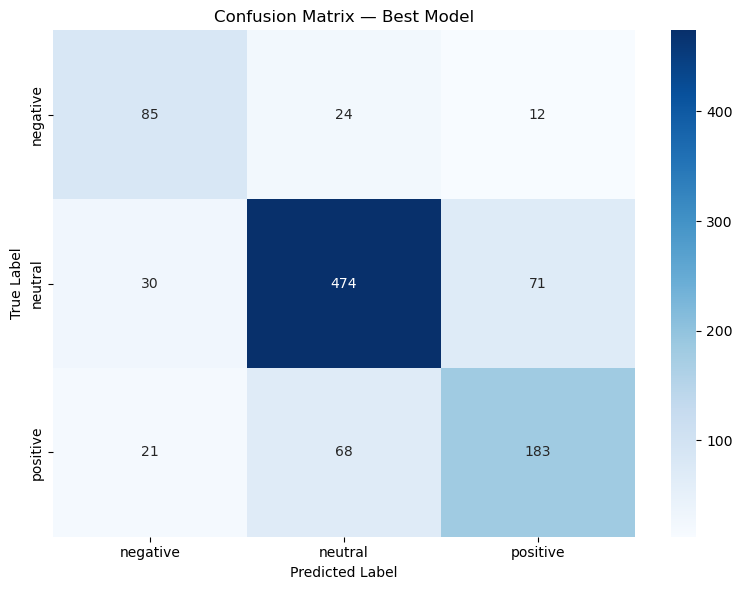

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

Path("reports").mkdir(exist_ok=True)

class_labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix — Best Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig(
    "reports/day05_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [32]:

label_names = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

# Создаём таблицу предсказаний
test_results = pd.DataFrame({
    "text": df_processed.loc[X_test.index, "text"].to_numpy(),
    "text_clean": X_test.to_numpy(),
    "true_label": y_test.to_numpy(),
    "predicted_label": y_pred_best
})

test_results["true_class"] = (
    test_results["true_label"].map(label_names)
)

test_results["predicted_class"] = (
    test_results["predicted_label"].map(label_names)
)

# Оставляем только ошибки
errors_df = test_results[
    test_results["true_label"] !=
    test_results["predicted_label"]
].copy()

print("Всего тестовых новостей:", len(test_results))
print("Правильных предсказаний:",
      len(test_results) - len(errors_df))
print("Ошибочных предсказаний:", len(errors_df))

print(f"Доля ошибок: {len(errors_df) / len(test_results):.2%}")

display(
    errors_df[
        ["text", "true_class", "predicted_class"]
    ].head(10)
)


Всего тестовых новостей: 968
Правильных предсказаний: 742
Ошибочных предсказаний: 226
Доля ошибок: 23.35%


,text,true_class,predicted_class
3,Net profit in the same period in 2006 was ( x...,neutral,negative
8,It projected revenue of $ 2.2 billion to $ 2.3...,positive,neutral
16,Sales fell abroad but increased in Finland .,neutral,negative
19,This new representation extends Comptel 's glo...,positive,neutral
21,"In the Asia-Pacific region , Visa Wave is avai...",positive,neutral
25,The contracts have been signed to acquire uran...,positive,negative
41,Finnish food company Raisio Oyj HEL : RAIVV sa...,neutral,positive
42,"Furthermore , Novator Finland Oy has entered i...",positive,neutral
46,The result before taxes was a loss of 25.0 mil...,neutral,negative
51,BAVARIA Industriekapital AG 's 2006 revenues w...,neutral,positive


In [33]:

# Группируем ошибки по истинному и предсказанному классу
error_types = (
    errors_df
    .groupby(["true_class", "predicted_class"])
    .size()
    .reset_index(name="error_count")
    .sort_values(
        "error_count",
        ascending=False
    )
)

# Доля каждого типа ошибки
if len(errors_df) > 0:
    error_types["error_share_pct"] = (
        error_types["error_count"]
        / len(errors_df) * 100
    ).round(2)
else:
    error_types["error_share_pct"] = []

print("=== ТИПЫ ОШИБОК ===")

display(error_types)


=== ТИПЫ ОШИБОК ===


,true_class,predicted_class,error_count,error_share_pct
3,neutral,positive,71,31.42
5,positive,neutral,68,30.09
2,neutral,negative,30,13.27
0,negative,neutral,24,10.62
4,positive,negative,21,9.29
1,negative,positive,12,5.31


In [34]:

print("=== ERROR ANALYSIS: REAL EXAMPLES ===")

for _, row in error_types.iterrows():

    true_class = row["true_class"]
    predicted_class = row["predicted_class"]

    examples = errors_df[
        (errors_df["true_class"] == true_class) &
        (errors_df["predicted_class"] == predicted_class)
    ].head(3)

    print("\n" + "=" * 70)
    print(f"TRUE: {true_class} -> PREDICTED: {predicted_class}")
    print(f"Всего ошибок этого типа: {row['error_count']}")
    print("=" * 70)

    for number, (_, example) in enumerate(
        examples.iterrows(), start=1
    ):
        print(f"\nПример {number}")
        print("Текст:", example["text"])
        print("Реальный класс:", example["true_class"])
        print("Предсказанный:", example["predicted_class"])


=== ERROR ANALYSIS: REAL EXAMPLES ===

TRUE: neutral -> PREDICTED: positive
Всего ошибок этого типа: 71

Пример 1
Текст: Finnish food company Raisio Oyj HEL : RAIVV said on Friday it has wrapped up the divestment of its margarine operations to US sector player Bunge Ltd NYSE : BG for EUR80m USD119 .2 m .
Реальный класс: neutral
Предсказанный: positive

Пример 2
Текст: BAVARIA Industriekapital AG 's 2006 revenues were EUR 333 million , with an EBITDA of EUR 51 million .
Реальный класс: neutral
Предсказанный: positive

Пример 3
Текст: I thank Jarmo Ukonaho warmly for his contribution and wish him all the best in the future challenges . ''
Реальный класс: neutral
Предсказанный: positive

TRUE: positive -> PREDICTED: neutral
Всего ошибок этого типа: 68

Пример 1
Текст: It projected revenue of $ 2.2 billion to $ 2.3 billion , slightly higher than analyst estimates of $ 2.19 billion .
Реальный класс: positive
Предсказанный: neutral

Пример 2
Текст: This new representation extends Comptel 's 

In [35]:

from pathlib import Path

Path("reports").mkdir(exist_ok=True)

# Сохраняем все ошибки
errors_df.to_csv(
    "reports/day05_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

# Статистика по типам ошибок
error_types.to_csv(
    "reports/day05_error_types.csv",
    index=False,
    encoding="utf-8-sig"
)

# Формируем текстовый отчёт
report_lines = [
    "DAY 5 — ERROR ANALYSIS",
    f"Best model: {best_name}",
    f"Test samples: {len(test_results)}",
    f"Correct predictions: {len(test_results) - len(errors_df)}",
    f"Incorrect predictions: {len(errors_df)}",
    f"Accuracy: {best_accuracy:.4f}",
    f"Macro F1: {best_f1:.4f}",
    "",
    "CLASSIFICATION REPORT",
    report_best,
    "",
    "MOST COMMON ERROR TYPES"
]

for _, row in error_types.iterrows():
    report_lines.append(
        f"{row['true_class']} -> {row['predicted_class']}: "
        f"{row['error_count']} errors "
        f"({row['error_share_pct']:.2f}%)"
    )

if not error_types.empty:
    top_error = error_types.iloc[0]

    report_lines.extend([
        "",
        "MAIN OBSERVATION",
        "Most frequent error:",
        f"{top_error['true_class']} -> "
        f"{top_error['predicted_class']}",
        f"Count: {top_error['error_count']}"
    ])

with open(
    "reports/day05_error_analysis.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(report_lines))

print("Файлы сохранены:")
print("reports/day05_confusion_matrix.png")
print("reports/day05_errors.csv")
print("reports/day05_error_types.csv")
print("reports/day05_error_analysis.txt")


Файлы сохранены:
reports/day05_confusion_matrix.png
reports/day05_errors.csv
reports/day05_error_types.csv
reports/day05_error_analysis.txt



## Итоги Дня 5 - Error Analysis

### 1. Оценка лучшей модели

Для анализа использована лучшая модель из Дня 4,
выбранная по результатам кросс-валидации.

Модель проверена на независимой тестовой выборке
из 968 финансовых новостей.

Рассчитаны Accuracy, Precision, Recall и Macro F1.

### 2. Confusion Matrix

Построена матрица ошибок для трёх классов:
- Negative
- Neutral
- Positive

Матрица позволяет определить, какие классы
модель чаще всего путает между собой.

### 3. Анализ ошибочных предсказаний

Создана таблица ошибочных предсказаний,
содержащая:
- Исходный текст новости.
- Истинную метку класса.
- Предсказанную метку класса.

Ошибки сгруппированы по сочетаниям
истинного и предсказанного классов.

### 4. Возможные причины ошибок

При ручном анализе необходимо проверить:

1. Неоднозначные финансовые формулировки.
2. Одновременное присутствие позитивных
   и негативных сигналов.
3. Редкие термины и словосочетания.
4. Недостаточное представительство отдельных
   классов в обучающей выборке.

Эти причины являются гипотезами и должны
быть подтверждены конкретными примерами.

### 5. Возможные улучшения

- Проверить другие значения class_weight.
- Попробовать подбор параметра C.
- Расширить обучающую выборку.
- Исследовать альтернативные признаки.
- Рассмотреть более сложные NLP-модели.

### 6. Заключение

Проведён анализ ошибок выбранной модели.
Получены Confusion Matrix, таблица ошибок
и статистика неправильных предсказаний.

Результаты позволяют определить направления
для дальнейшего улучшения классификации.



# День 6 - Inference Pipeline и сохранение модели

**Цель:** реализовать полноценный механизм предсказания
тональности новых финансовых новостей без переобучения.

### Задачи

1. Сохранить лучшую модель и TF-IDF vectorizer.
2. Загрузить обученную модель из файла.
3. Реализовать функцию `predict_sentiment()`.
4. Использовать preprocessing из Дня 2.
5. Проверить предсказания на новых текстах.
6. Описать формат входных и выходных данных.

**Модель:** TF-IDF + Logistic Regression Balanced.

**Классы:**
- 0 - negative
- 1 - neutral
- 2 - positive

Модель обучена на англоязычных финансовых новостях.


In [36]:

import joblib
import json
from pathlib import Path

# Создаём папку для моделей
Path("models").mkdir(exist_ok=True)

# Загружаем лучшую модель, сохранённую в День 4.
# Если файла нет, используем best_model из текущего Notebook.

day04_path = Path("models/day04_best_model.joblib")

if day04_path.exists():
    model_to_save = joblib.load(day04_path)
elif "best_model" in globals():
    model_to_save = best_model
else:
    raise FileNotFoundError(
        "Сначала выполни ячейки Дня 4 или "
        "восстанови models/day04_best_model.joblib"
    )

# Сохраняем полный Pipeline
joblib.dump(
    model_to_save,
    "models/day06_inference_pipeline.joblib"
)

# Сохраняем TF-IDF отдельно
joblib.dump(
    model_to_save.named_steps["tfidf"],
    "models/day06_vectorizer.joblib"
)

# Сохраняем классификатор отдельно
joblib.dump(
    model_to_save.named_steps["classifier"],
    "models/day06_classifier.joblib"
)

# Сохраняем метки классов
label_mapping = {
    "0": "negative",
    "1": "neutral",
    "2": "positive"
}

with open(
    "models/day06_labels.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(label_mapping, f, indent=4)

print("Модель и компоненты успешно сохранены!")


Модель и компоненты успешно сохранены!


In [37]:

# Загружаем сохранённую модель
inference_model = joblib.load(
    "models/day06_inference_pipeline.joblib"
)

# Проверяем структуру Pipeline
print("Модель загружена!")
print("\nСтруктура:")
print(inference_model)

print("\nКлассы модели:")
print(inference_model.classes_)

# Проверяем, что preprocessing из Дня 2 доступен
if "clean_text" not in globals():
    raise RuntimeError(
        "Выполни ячейку с функцией clean_text() из Дня 2"
    )

print("\nPreprocessing доступен!")


Модель загружена!

Структура:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

Классы модели:
[0 1 2]

Preprocessing доступен!


In [38]:

import pandas as pd

LABEL_NAMES = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

def predict_sentiment(texts):
    """
    Предсказание тональности финансовых новостей.

    Input:
        str или list[str] — английские финансовые тексты.

    Output:
        pd.DataFrame:
        - text: исходный текст
        - text_clean: очищенный текст
        - label: числовой класс
        - sentiment: название класса
        - confidence: максимальная вероятность,
          если модель поддерживает predict_proba
    """

    # Принимаем одну строку или список строк
    if isinstance(texts, str):
        texts = [texts]
    elif isinstance(texts, (list, tuple)):
        texts = list(texts)
    else:
        raise TypeError(
            "Ожидается строка или список строк"
        )

    if not texts:
        raise ValueError("Список текстов пуст")

    if not all(isinstance(t, str) for t in texts):
        raise TypeError("Все элементы должны быть строками")

    # Используем функцию из Дня 2
    cleaned_texts = [clean_text(t) for t in texts]

    # Проверяем пустые тексты после очистки
    if any(not t for t in cleaned_texts):
        raise ValueError(
            "Обнаружен пустой текст после preprocessing"
        )

    # Предсказание без переобучения
    predictions = inference_model.predict(cleaned_texts)

    result = pd.DataFrame({
        "text": texts,
        "text_clean": cleaned_texts,
        "label": predictions.astype(int),
        "sentiment": [
            LABEL_NAMES[int(p)] for p in predictions
        ]
    })

    # Вероятности, если модель их поддерживает
    if hasattr(inference_model, "predict_proba"):
        probabilities = inference_model.predict_proba(
            cleaned_texts
        )

        result["confidence"] = probabilities.max(
            axis=1
        ).round(4)

        for idx, class_id in enumerate(
            inference_model.classes_
        ):
            class_name = LABEL_NAMES[int(class_id)]
            result[f"p_{class_name}"] = (
                probabilities[:, idx].round(4)
            )

    return result


print("Функция predict_sentiment() готова!")


Функция predict_sentiment() готова!


In [39]:

new_texts = [
    # Позитивная новость
    "Apple reported record profits and revenue increased by 25%.",

    # Негативная новость
    "The company reported massive losses and announced 500 layoffs.",

    # Нейтральная новость
    "The board of directors will meet on Monday.",

    # Позитивная новость
    "Tesla shares surged after better than expected earnings.",

    # Негативная новость
    "Sales declined by 15% and the company lowered its forecast."
]

predictions_df = predict_sentiment(new_texts)

display(predictions_df)

print("\n=== РЕЗУЛЬТАТЫ ===")

for _, row in predictions_df.iterrows():
    print("Новость:", row["text"])
    print("Тональность:", row["sentiment"])

    if "confidence" in predictions_df.columns:
        print(f"Confidence: {row['confidence']:.2%}")

    print("-" * 60)


,text,text_clean,label,sentiment,confidence,p_negative,p_neutral,p_positive
0,Apple reported record profits and revenue incr...,apple reported record profits and revenue incr...,2,positive,0.7035,0.0854,0.2111,0.7035
1,The company reported massive losses and announ...,the company reported massive losses and announ...,0,negative,0.4248,0.4248,0.3882,0.1870
2,The board of directors will meet on Monday.,the board of directors will meet on monday.,1,neutral,0.8585,0.0476,0.8585,0.0940
3,Tesla shares surged after better than expected...,tesla shares surged after better than expected...,0,negative,0.4603,0.4603,0.2001,0.3397
4,Sales declined by 15% and the company lowered ...,sales declined by 15% and the company lowered ...,0,negative,0.5046,0.5046,0.2142,0.2812



=== РЕЗУЛЬТАТЫ ===
Новость: Apple reported record profits and revenue increased by 25%.
Тональность: positive
Confidence: 70.35%
------------------------------------------------------------
Новость: The company reported massive losses and announced 500 layoffs.
Тональность: negative
Confidence: 42.48%
------------------------------------------------------------
Новость: The board of directors will meet on Monday.
Тональность: neutral
Confidence: 85.85%
------------------------------------------------------------
Новость: Tesla shares surged after better than expected earnings.
Тональность: negative
Confidence: 46.03%
------------------------------------------------------------
Новость: Sales declined by 15% and the company lowered its forecast.
Тональность: negative
Confidence: 50.46%
------------------------------------------------------------


In [40]:

# Одна новость
single_news = (
    "Microsoft announced a significant increase "
    "in quarterly revenue."
)

single_prediction = predict_sentiment(single_news)

print("Предсказание для одной новости:")
display(single_prediction)

# Проверяем некорректные значения
invalid_examples = [
    "",
    "    ",
    "<p></p>",
    [],
    None
]

print("\nПроверка некорректного ввода:")

for example in invalid_examples:
    try:
        predict_sentiment(example)
        print("Неожиданно принят:", repr(example))
    except (ValueError, TypeError) as error:
        print(f"{example!r}: {error}")


Предсказание для одной новости:


,text,text_clean,label,sentiment,confidence,p_negative,p_neutral,p_positive
0,Microsoft announced a significant increase in ...,microsoft announced a significant increase in ...,2,positive,0.7154,0.04,0.2446,0.7154



Проверка некорректного ввода:
'': Обнаружен пустой текст после preprocessing
'    ': Обнаружен пустой текст после preprocessing
'<p></p>': Обнаружен пустой текст после preprocessing
[]: Список текстов пуст
None: Ожидается строка или список строк


In [41]:

import numpy as np

saved_vectorizer = joblib.load(
    "models/day06_vectorizer.joblib"
)

saved_classifier = joblib.load(
    "models/day06_classifier.joblib"
)

examples_clean = [clean_text(t) for t in new_texts]

# Полный Pipeline
pipeline_predictions = inference_model.predict(
    examples_clean
)

# Отдельные компоненты
X_vectorized = saved_vectorizer.transform(
    examples_clean
)

component_predictions = saved_classifier.predict(
    X_vectorized
)

np.testing.assert_array_equal(
    pipeline_predictions,
    component_predictions
)

print("Проверка пройдена!")
print("Pipeline и отдельные компоненты")
print("возвращают одинаковые классы.")


Проверка пройдена!
Pipeline и отдельные компоненты
возвращают одинаковые классы.


In [42]:

from pathlib import Path

Path("reports").mkdir(exist_ok=True)

predictions_df.to_csv(
    "reports/day06_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Предсказания сохранены:")
print("reports/day06_predictions.csv")


Предсказания сохранены:
reports/day06_predictions.csv



## Итоги Дня 6 - Inference Pipeline

### 1. Сохранение модели

Для inference используется лучшая модель,
выбранная по результатам Дня 4:

**TF-IDF + Logistic Regression Balanced.**

Сохранены:
- Полный Pipeline в формате joblib.
- TF-IDF vectorizer.
- Обученный классификатор.
- Соответствие числовых и текстовых меток.

### 2. Реализация inference

Создана функция `predict_sentiment()`.

Функция выполняет:
1. Проверку входных данных.
2. Очистку текста через `clean_text()` из Дня 2.
3. TF-IDF преобразование.
4. Классификацию текста.
5. Формирование результата.

Повторное обучение модели не требуется.

### 3. Формат входных данных

Функция принимает:

**Один текст:**
`predict_sentiment("Company profits increased.")`

**Список текстов:**
`predict_sentiment(["News 1", "News 2"])`

Поддерживаются англоязычные финансовые новости.

### 4. Формат выходных данных

Результат возвращается как pandas DataFrame:

- `text` — оригинальный текст.
- `text_clean` — очищенный текст.
- `label` — числовой класс.
- `sentiment` — текстовая метка.
- `confidence` — уверенность модели (если доступна).
- `p_negative`, `p_neutral`, `p_positive` —
  вероятности классов (если доступны).

Классы:
- 0: negative
- 1: neutral
- 2: positive

### 5. Проверки

Проверены:
- Предсказание для одной новости.
- Предсказание для списка новостей.
- Обработка пустого и некорректного ввода.
- Загрузка модели из joblib.
- Совпадение результатов полного Pipeline
  и отдельно сохранённых компонентов.

### 6. Заключение

Реализован inference pipeline для классификации
новых финансовых новостей.

Система умеет загружать обученную модель,
применять preprocessing и делать предсказания
без повторного обучения.

Модель готова к финальной интеграции проекта.


# День 7 - Финализация Classification Mini-Product

**Проект:** Financial News Sentiment Classification

**Цель:** объединить все этапы машинного обучения
в законченный и воспроизводимый ML mini-product.

### План

1. Проверить результаты предыдущих этапов.
2. Проверить сохранение и загрузку лучшей модели.
3. Подготовить демонстрационные предсказания.
4. Создать автономный inference-скрипт.
5. Подготовить README и requirements.txt.
6. Проверить запуск без переобучения.
7. Документировать результаты и ограничения.

### Архитектура

Data → EDA → Preprocessing → Train/Test Split
→ TF-IDF → Model Training → Evaluation
→ Error Analysis → Model Saving → Inference

**Основная метрика качества:** Macro F1.

In [43]:

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import json

from sklearn.metrics import accuracy_score, f1_score

# Проверяем результат предыдущих дней
assert len(df_processed) == 4836
assert len(X_train) == 3868
assert len(X_test) == 968

assert df_processed["text_clean"].notna().all()
assert df_processed["text_clean"].str.len().gt(0).all()
assert df_processed["label"].isin([0, 1, 2]).all()

# Загружаем сохранённый Pipeline из Дня 6
model_path = Path("models/day06_inference_pipeline.joblib")

assert model_path.exists(), (
    "Не найден Pipeline. Выполни сохранение модели из Дня 6."
)

final_model = joblib.load(model_path)

# Проверяем предсказания сохранённой модели
final_predictions = final_model.predict(X_test)

np.testing.assert_array_equal(
    final_predictions,
    best_model.predict(X_test)
)

final_accuracy = accuracy_score(
    y_test, final_predictions
)

final_macro_f1 = f1_score(
    y_test,
    final_predictions,
    average="macro",
    zero_division=0
)

print("=== FINAL MODEL CHECK ===")
print("Лучшая модель:", best_name)
print("Всего записей:", len(df_processed))
print("Train:", len(X_train))
print("Test:", len(X_test))
print(f"Baseline Macro F1: {baseline_f1:.4f}")
print(f"Final Macro F1: {final_macro_f1:.4f}")
print(f"Final Accuracy: {final_accuracy:.4f}")

assert np.isclose(final_macro_f1, best_f1)

print("\nМодель успешно загружена и проверена!")


=== FINAL MODEL CHECK ===
Лучшая модель: LogReg Balanced
Всего записей: 4836
Train: 3868
Test: 968
Baseline Macro F1: 0.6888
Final Macro F1: 0.7242
Final Accuracy: 0.7665

Модель успешно загружена и проверена!


In [44]:

demo_texts = [
    "The company reported record revenue and strong profit growth.",

    "The company announced massive layoffs after heavy losses.",

    "The board of directors will meet next Thursday.",

    "Quarterly earnings exceeded analyst expectations by 15%.",

    "Sales declined sharply and the company lowered its forecast."
]

demo_clean = [clean_text(t) for t in demo_texts]

demo_pred = final_model.predict(demo_clean)

label_names = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

demo_df = pd.DataFrame({
    "text": demo_texts,
    "prediction": [
        label_names[int(p)] for p in demo_pred
    ]
})

if hasattr(final_model, "predict_proba"):
    probabilities = final_model.predict_proba(demo_clean)
    demo_df["confidence"] = probabilities.max(axis=1).round(4)

display(demo_df)

# Сохраняем demo
Path("reports").mkdir(exist_ok=True)

demo_df.to_csv(
    "reports/day07_demo.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Demo сохранено: reports/day07_demo.csv")


,text,prediction,confidence
0,The company reported record revenue and strong...,positive,0.7697
1,The company announced massive layoffs after he...,negative,0.4607
2,The board of directors will meet next Thursday.,neutral,0.8251
3,Quarterly earnings exceeded analyst expectatio...,positive,0.4415
4,Sales declined sharply and the company lowered...,negative,0.4344


Demo сохранено: reports/day07_demo.csv


In [45]:

from pathlib import Path

cli_code = r'''
import argparse
import html
import json
import re
from pathlib import Path

import joblib

MODEL_PATH = (
    Path(__file__).resolve().parent
    / "models/day06_inference_pipeline.joblib"
)

LABELS = {
    0: "negative",
    1: "neutral",
    2: "positive"
}


def clean_text(text):
    """Очистка, аналогичная preprocessing Дня 2."""
    if not isinstance(text, str):
        return ""

    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    return re.sub(r"\s+", " ", text).strip()


def predict_sentiment(texts):
    """Классификация одной или нескольких новостей."""
    if isinstance(texts, str):
        texts = [texts]

    if not isinstance(texts, list) or not texts:
        raise ValueError("Ожидается непустой список строк")

    cleaned = [clean_text(t) for t in texts]

    if any(not t for t in cleaned):
        raise ValueError("Пустой или некорректный текст")

    # Загружаем обученную модель без вызова fit()
    model = joblib.load(MODEL_PATH)

    predictions = model.predict(cleaned)

    probabilities = (
        model.predict_proba(cleaned)
        if hasattr(model, "predict_proba")
        else None
    )

    results = []

    for i, (text, label) in enumerate(
        zip(texts, predictions)
    ):
        item = {
            "text": text,
            "label": int(label),
            "sentiment": LABELS[int(label)]
        }

        if probabilities is not None:
            item["confidence"] = round(
                float(probabilities[i].max()), 4
            )

        results.append(item)

    return results


if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Financial News Sentiment Classification"
    )

    parser.add_argument(
        "--text",
        action="append",
        required=True,
        help="English financial news"
    )

    args = parser.parse_args()

    results = predict_sentiment(args.text)

    print(json.dumps(
        results,
        indent=2,
        ensure_ascii=False
    ))
'''

Path("predict_cli.py").write_text(
    cli_code.strip() + "\n",
    encoding="utf-8"
)

print("Файл predict_cli.py создан!")


Файл predict_cli.py создан!


In [46]:

import subprocess
import sys
import json

from predict_cli import (
    predict_sentiment as cli_predict,
    clean_text as cli_clean_text
)

# Проверяем совпадение preprocessing
for text in demo_texts:
    assert clean_text(text) == cli_clean_text(text)

# Предсказания внутри Notebook
notebook_predictions = final_model.predict(
    [clean_text(t) for t in demo_texts]
)

# Предсказания автономного скрипта
cli_results = cli_predict(demo_texts)

cli_predictions = [
    item["label"] for item in cli_results
]

np.testing.assert_array_equal(
    notebook_predictions,
    cli_predictions
)

# Проверяем работу CLI как отдельной программы
process = subprocess.run(
    [
        sys.executable,
        "predict_cli.py",
        "--text",
        "The company reported record profits."
    ],
    capture_output=True,
    text=True,
    check=True
)

cli_output = json.loads(process.stdout)

assert len(cli_output) == 1
assert cli_output[0]["sentiment"] in [
    "negative", "neutral", "positive"
]

print("Все проверки пройдены!")
print("Preprocessing совпадает.")
print("Предсказания Notebook и CLI совпадают.")
print("Автономный запуск работает.")
print("\nРезультат CLI:")
print(json.dumps(cli_output, indent=2))


Все проверки пройдены!
Preprocessing совпадает.
Предсказания Notebook и CLI совпадают.
Автономный запуск работает.

Результат CLI:
[
  {
    "text": "The company reported record profits.",
    "label": 1,
    "sentiment": "neutral",
    "confidence": 0.4918
  }
]


In [50]:

from pathlib import Path
import joblib
import numpy as np

# Обязательные файлы для сдачи
required_files = {
    "EDA: распределение классов":
        "sentiment_distribution.png",

    "EDA: длины текстов":
        "text_length_distribution.png",

    "Сравнение моделей":
        "reports/day04_comparison.csv",

    "Confusion Matrix":
        "reports/day05_confusion_matrix.png",

    "Анализ ошибок":
        "reports/day05_error_analysis.txt",

    "Лучшая модель":
        "models/day06_inference_pipeline.joblib",

    "Inference CLI":
        "predict_cli.py",

    "Demo":
        "reports/day07_demo.csv",

    "README":
        "README.md",

    "Зависимости":
        "requirements.txt"
}

print("=== FINAL PROJECT VALIDATION ===\n")

missing_files = []

for description, filename in required_files.items():
    if Path(filename).is_file():
        print(f"[OK] {description}")
    else:
        print(f"[MISSING] {description}: {filename}")
        missing_files.append(filename)

# Проверяем, что модель загружается
model_path = Path(
    "models/day06_inference_pipeline.joblib"
)

if model_path.exists():
    model = joblib.load(model_path)

    test_news = [
        "The company reported record profits."
    ]

    cleaned = [clean_text(text) for text in test_news]
    predictions = model.predict(cleaned)

    assert int(predictions[0]) in [0, 1, 2]
    print("\n[OK] Model inference")

print("\n=== RESULTS ===")

if not missing_files:
    print("Все обязательные файлы найдены!")
else:
    print("Отсутствует файлов:", len(missing_files))
    print("Создай недостающие файлы перед сдачей.")

print("\nBaseline Macro F1:", round(baseline_f1, 4))
print("Best CV Macro F1:", round(best_cv_f1, 4))
print("Best Test Macro F1:", round(best_f1, 4))
print("Errors:", len(errors_df))


=== FINAL PROJECT VALIDATION ===

[OK] EDA: распределение классов
[OK] EDA: длины текстов
[OK] Сравнение моделей
[OK] Confusion Matrix
[OK] Анализ ошибок
[OK] Лучшая модель
[OK] Inference CLI
[OK] Demo
[OK] README
[OK] Зависимости

[OK] Model inference

=== RESULTS ===
Все обязательные файлы найдены!

Baseline Macro F1: 0.6888
Best CV Macro F1: 0.72
Best Test Macro F1: 0.7242
Errors: 226
